## Fairness, Accountability, Transparency and Ethics Course (FATE)
## Universitat Pompeu Fabra (UPF)
### Academic Year 2025-2026
### Author: Ashwin Singh (ashwin.singh01@estudiant.upf.edu)
*** Partially based on the original exercises made by David Solans (david.solans@upf.edu) ***

Submission date: 03/02/2025 at 23:59 on Aula Global

Please work on this notebook **individually**.

# LAB 1: Data anonymization with Python

# Getting Started

## Imports

In [1]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from scipy.stats import pearsonr

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import random

In [2]:
import warnings

warnings.filterwarnings(action="ignore")

## Loading Dataset
In this section we will use a synthetic dataset containing medical records of 100 users.

In [3]:
dataset_url = "https://raw.githubusercontent.com/Ashwin-19/UPF-FATE-2025/refs/heads/main/Lab%20I%20-%20Data%20Anonymization/Data/health_dataset.csv"
health_data = pd.read_csv(dataset_url)
health_data.head()

,PatientName,SSN,PatientID,Phone,Gender,BirthDate,ZipCode,Health Condition,Weight,Height
0,Pablo de Cobo,412-92-6881,1000,+34 738 644 211,Male,20011009,8003,Bird flu,80,184
1,Fabio Menendez Velasco,265-27-3243,1001,+34742032426,Male,20010110,8003,Bird flu,79,179
2,Flavia Cabañas Cabanillas,554-97-8002,1002,+34712747631,Female,20010101,8014,Bird flu,67,172
3,Eliana Vendrell-Vilalta,990-49-6929,1003,+34 712 466 137,Female,20001009,8002,Common cold and flu,93,184
4,César Mas Silva,833-83-9451,1004,+34716 22 73 14,Male,20000101,8002,Common cold and flu,66,171


## Types of Identifiers and Attributes [ 1 pts ]



**[ 0.5 pts ]** List the identifiers and quasi-identifiers in the dataset:

**[ Answer ]**
Identifiers are:

PatientName,
SSN,
PatientID,
Phone
Quasi-identifier are :

Gender,
BirthDate,
ZipCode,
Weight,
Height

**[ 0.5 pts ]** List the confidential attributes in the dataset.

**[ Answer ]**
The confidential attributes:
Health Condition,
SSN

## Data Filtering [ 0.5 pts ]

**[ 0.5 pts ]** Remove/Suppress the columns including personally identifiable information from the dataset.

**[ Discuss ]** Why do we remove/supress them?
We want to remove or supress them to protect the privacy of people involved and not to risk re-indetification. Another reason of removing them would be because of the minimisation principle.

In [5]:
pii_columns = ['PatientName', 'SSN', 'PatientID', 'Phone']
health_data = health_data[pii_columns]
health_data.head()

,PatientName,SSN,PatientID,Phone
0,Pablo de Cobo,412-92-6881,1000,+34 738 644 211
1,Fabio Menendez Velasco,265-27-3243,1001,+34742032426
2,Flavia Cabañas Cabanillas,554-97-8002,1002,+34712747631
3,Eliana Vendrell-Vilalta,990-49-6929,1003,+34 712 466 137
4,César Mas Silva,833-83-9451,1004,+34716 22 73 14


# K-Anonymity

## Checking K-Anonymity [ 2 pts ]

**[ 1.5 pts ]** Create a function which checks whether the data sastifies k-anonimity given some quasi-identifiers. Also return the maximum k for which the quasi-identifiers satisfy k-anonymity.

In [6]:
from collections import Counter

def is_k_anonymous(data, quasi_identifiers):
    """
    Determines whether the data is k-anonymous based on quasi-identifiers
    and finds the maximum k for which k-anonymity is satisfied.

    Args:
        data (pandas.DataFrame): The dataset containing microdata.
        quasi_identifiers (list): The list of quasi-identifiers.

    Returns:
        bool: True if the dataset is k-anonymous, False otherwise.
        int: Maximum k for which k-anonymity is satisfied.
    """
    grouped_counts = data.groupby(quasi_identifiers).size()

    min_k = grouped_counts.min()

    return min_k >= 2, min_k


**[ 0.25 pts ]** Is the data k-anonymous for BirthDate and ZipCode? If so, what is the maximum k for which k-anonymity is satisfied?

In [7]:
is_k_anonymous(health_data, ["BirthDate", "ZipCode"])

(False, 1)

The data is not k-anonymous for BirthDate and ZipCode because there is only one instance for each combination.

**[ 0.25 pts ]** Is the data k-anonymous for Gender and ZipCode? If so, what is the maximum k for which k-anonymity is satisfied?

In [9]:
is_k_anonymous(health_data, ["Gender", "ZipCode"])

(True, 3)

## Testing K-Anonimity [ 1 pts ]

To test our function, we will use a dataset from the example given in the [K-Anonymity article](https://en.wikipedia.org/wiki/K-anonymity) on Wikipedia and satisfies 2-anonymity for any combination of the attributes ``Age``, ``Gender`` and ``State of domicile``.

In [10]:
wiki_data = pd.read_html("https://en.wikipedia.org/wiki/K-anonymity",header=0)[1]
wiki_data

,Name,Age,Gender,Height,Weight,State of domicile,Religion,Disease
0,*,20 < Age ≤ 30,Female,165 cm,72 kg,Tamil Nadu,*,Cancer
1,*,20 < Age ≤ 30,Female,162 cm,70 kg,Kerala,*,Viral infection
2,*,20 < Age ≤ 30,Female,170 cm,68 kg,Tamil Nadu,*,Tuberculosis
3,*,20 < Age ≤ 30,Male,170 cm,75 kg,Karnataka,*,No illness
4,*,20 < Age ≤ 30,Female,165 cm,71 kg,Kerala,*,Heart-related
5,*,20 < Age ≤ 30,Male,160 cm,69 kg,Karnataka,*,Tuberculosis
6,*,Age ≤ 20,Male,167 cm,85 kg,Kerala,*,Cancer
7,*,20 < Age ≤ 30,Male,180 cm,81 kg,Karnataka,*,Heart-related
8,*,Age ≤ 20,Male,175 cm,79 kg,Kerala,*,Heart-related
9,*,Age ≤ 20,Male,169 cm,82 kg,Kerala,*,Viral infection


**[ 1 pts ]** Test k-anonimity for the three attributes and their different combinations picking two attributes at a time. For each combination, find the maximum k satisfying k-anonymity.

In [13]:
pairs = [
    ("Age", "Gender"),
    ("Age", "State of domicile"),
    ("Age", "Disease"),
    ("Gender", "State of domicile"),
    ("Gender", "Disease"),
    ("State of domicile", "Disease")
]
for pair in pairs:
  print(is_k_anonymous(wiki_data, list(pair)))

(True, 3)
(True, 2)
(False, 1)
(True, 2)
(False, 1)
(False, 1)


## Properties of K-Anonymity [ 1 pts ]
> You may use examples from the previous exercises.

**[ 0.5 pts ]** If a dataset is $k_1$-anonymous for a set of attributes, and $k_2$-anonymous for any subset of those attributes, what is the relationship between $k_1$ and $k_2$? Can you show an example?

**[ Answer ]**
k2>=k1 in all cases, since k2 is a subset of k1, thus having less attributes will only make more identical records.
For example, if we use all attributes: Age, Gender and State of domicile, the smallest k1 = 1. In the case you remove State of domicile, the smallest k2 = 3. As seen, k2>=k1.


**[ 0.5 pts ]** If a dataset is $k_1$-anonymous given an attribute $a_1$, and $k_2$-anonymous given an attribute $a_2$, is the dataset always $k$-anonymous given attributes $\{a_1,a_2\}$ ? If not, show an example, and find the maximum $k$ for which the dataset can be $k$-anonymous.

**[ Answer ]**
No, this is not the case. Let's see a counterexampple. In the case of age, k1=3 and Gender k2=4. Age and Gender have a k = 3 instead of the maximum 4.

## Methods for K-Anonymity [ 5 pts ]

### GLOBAL Recoding (Generalization)

**[ 0.25 pts ]** Create a function which applies **global recoding** to an attribute in the data upto $n$ digits.

In [6]:
def global_recoding(data, attribute, n):
    """
    Applies global recoding to an attribute in the data for n digits.

    Args:
        data (pandas.DataFrame): Data for anonymization.
        attribute (str): Attribute to be recoded.
        n (int): Number of digits to be recoded.

    Returns:
        pandas.DataFrame: Globally recoded data.
    """
    data = data.copy()
    data[attribute] = data[attribute].astype(str).apply(lambda x: x[:n] + '*' * (len(x) - n))
    return data

**[ 0.75 pts ]** Use the function to list all possible ways of 3-anonymizing the dataset given attributes ``BirthDate`` and ``ZipCode``. What is the best way of 3-anonymizing the dataset if we want to preserve maximum information about the health conditions across different zip codes?

**[ Answer ]**

In [7]:
# your code here
#all possible ways
anonymized_data = global_recoding(health_data, "BirthDate", 4)
anonymized_data = global_recoding(anonymized_data, "ZipCode", 1)

anonymized_data = global_recoding(health_data, "BirthDate", 2)
anonymized_data = global_recoding(anonymized_data, "ZipCode", 1)

anonymized_data = global_recoding(health_data, "BirthDate", 2)
anonymized_data = global_recoding(anonymized_data, "ZipCode", 2)

#best way to 3-anonymize the dataset
anonymized_data = global_recoding(health_data, "BirthDate", 4)
anonymized_data = global_recoding(anonymized_data, "ZipCode", 2)
anonymized_data

,PatientName,SSN,PatientID,Phone,Gender,BirthDate,ZipCode,Health Condition,Weight,Height
0,Pablo de Cobo,412-92-6881,1000,+34 738 644 211,Male,2001****,80**,Bird flu,80,184
1,Fabio Menendez Velasco,265-27-3243,1001,+34742032426,Male,2001****,80**,Bird flu,79,179
2,Flavia Cabañas Cabanillas,554-97-8002,1002,+34712747631,Female,2001****,80**,Bird flu,67,172
3,Eliana Vendrell-Vilalta,990-49-6929,1003,+34 712 466 137,Female,2000****,80**,Common cold and flu,93,184
4,César Mas Silva,833-83-9451,1004,+34716 22 73 14,Male,2000****,80**,Common cold and flu,66,171
...,...,...,...,...,...,...,...,...,...,...
95,Edu Jara Mendez,710-89-6575,1095,+34606 44 46 92,Female,2000****,80**,Bird flu,62,165
96,Juliana Cruz Vargas Rosselló,938-96-5737,1096,+34822 68 89 86,Female,2001****,80**,Asthma,61,151
97,Fidel Robledo Hernando,102-30-5721,1097,+34 872 667 558,Male,2000****,80**,Common cold and flu,62,188
98,Hilda Mamen Villaverde Castrillo,360-89-8456,1098,+34713200463,Female,2000****,80**,Common cold and flu,64,179


**[ 1 pts ]** For the best way of $3$-anonymizing the dataset from last question, comment on the sufficiency of $k$-anonymity against **homogeneity** and **internal** attacks aimed at inferring the health condition of patients. If you find $k$-anonymity to be insufficient, you must show quasi-identifier equivalence classes (groups) susceptible to the attacks.

𝑘-anonymity is not enough against homogeneity and internal attacks because we have the same conditions for some groups with the same birthyear and zipcode, thus making inferring easy.

In [11]:
# your code here
def analyze_equivalence_classes(data, quasi_identifiers, sensitive_attr):
    grouped = data.groupby(quasi_identifiers)
    for key, group in grouped:
        print(f"Group {key}:\n", group[[sensitive_attr]])
        if group[sensitive_attr].nunique() == 1:
            print(" Homogeneity risk since all values are the same")
        if len(group) < 3:
            print("Insufficient k-anonymity")

### Microaggregation

**[ 2 pts ]** Create a function which microaggregates continuous attributes (``height, weight``) to achieve $k$-anonymity, while minimizing the loss in information across both attributes. Return the best-possible $k$-anonymity and corresponding loss.

**Recommended Approach**: Experiment with a clustering algorithm for $n \leq \frac{|Data|}{k}$ clusters to achieve $k$-anonymity, and use sum of squared errors between original and anonymized data for loss of information.

In [13]:
def microaggregation(data, attributes, k):
    """
    Applies microaggregation to attributes in the data
    to achieve k'-anonymity, k' >= k.

    Args:
        data (pandas.DataFrame): Data for anonymization.
        attributes (list): Attributes to be microaggregated.
        k (int): Lower bound of k-anonymity to achieve.

    Returns:
        tuple:
            float: Loss of information to achieve k' anonymity.
            int: k' corresponding to k'-anonymity achieved.
    """
    data = data.copy()
    X = data[attributes].values
    n_clusters = max(len(X) // k, 1)

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    data['Cluster'] = kmeans.fit_predict(X)

    cluster_means = data.groupby('Cluster')[attributes].transform('mean')

    loss = np.sum((X - cluster_means.values) ** 2)

    data[attributes] = cluster_means

    observed_k = data['Cluster'].value_counts().min()
    data.drop(columns=['Cluster'], inplace=True)

    return data, loss, observed_k

**[ 1 pts ]** Plot the relationship between $k$-anonymity achieved v/s loss of information for $k \in \{2,3,4,...10\}$. What do you observe?

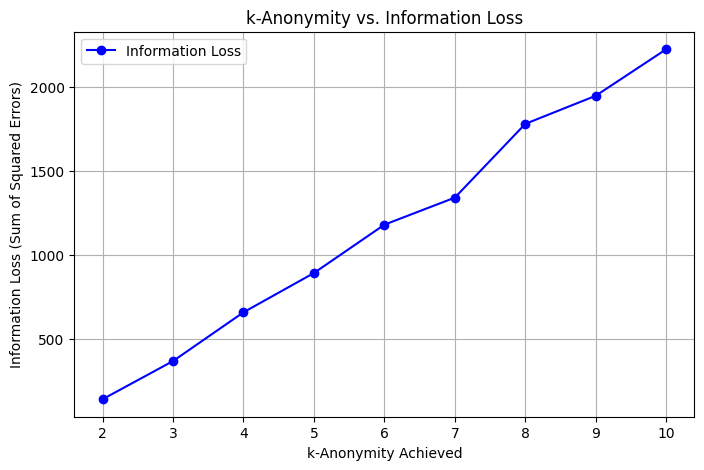

([1, 1, 1, 1, 1, 3, 4, 3, 5],
 [139.14999999999998,
  366.45000000000005,
  656.905303030303,
  890.8396825396825,
  1178.661940836941,
  1339.937987012987,
  1779.167243867244,
  1946.6070096570097,
  2223.7328754578753])

In [15]:
# your code here

k_values = range(2, 11)
losses = []
observed_k_values = []


for k in k_values:
    _, loss, observed_k = microaggregation(health_data, ["Weight", "Height"], k)
    losses.append(loss)
    observed_k_values.append(observed_k)


plt.figure(figsize=(8, 5))
plt.plot(k_values, losses, marker='o', linestyle='-', color='b', label="Information Loss")
plt.xlabel("k-Anonymity Achieved")
plt.ylabel("Information Loss (Sum of Squared Errors)")
plt.title("k-Anonymity vs. Information Loss")
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.show()


observed_k_values, losses

# L-Diversity

## Checking L-Diversity [ 1.5 pts ]

**[ 0.5 pts ]** Create a function which checks whether a dataset is l-diverse given a sensitive attribute and quasi-identifiers. If so, return the maximum-l for which the dataset satisfies l-diversity.

In [4]:
def is_l_diverse(data, sensitive, quasi_identifiers):
    """
    Checks whether a data is l-diverse for a sensitive
    attribute given quasi-identifiers, and returns the
    maximum l for which the data satisfies l-diversity.

    Args:
        data (pandas.DataFrame): Data to check l-diversity for.
        sensitive (str): Sensitive attribute for l-diversity.
        quasi_identifiers (list): List of quasi-identifiers.

    Returns:
        tuple:
            bool: Indicating whether the data is l-diverse.
            int: Maximum l for which the data satisfies l-diversity.
    """
    grouped = data.groupby(quasi_identifiers)[sensitive].nunique()
    l = grouped.min()
    return l >= 2, l


> Answer the following questions for the original dataset, globally recoded dataset.

**[ 0.5 pts ]** Is the dataset l-diverse given ``Health Condition`` as sensitive attribute and ``ZipCode, BirthDate`` as quasi-identifiers?

In [8]:
# your code here
is_l_diverse(health_data, 'Health Condition', ['ZipCode', 'BirthDate'])

(False, 1)

In [9]:
is_l_diverse(anonymized_data, 'Health Condition', ['ZipCode', 'BirthDate'])

(True, 4)

**[ 0.5 pts ]** Is the dataset l-diverse given ``Gender`` as sensitive attribute and ``ZipCode, BirthDate`` as quasi-identifiers?

In [10]:
# your code here
is_l_diverse(health_data, 'Gender', ['ZipCode', 'BirthDate'])

(False, 1)

In [11]:
# your code here
is_l_diverse(anonymized_data, 'Gender', ['ZipCode', 'BirthDate'])

(True, 2)

## L-Diversity via Local Suppression [ 2 pts ]

**[ 1 pts ]** Create a function to apply local suppression to groups within a $k$-anonymized dataset which violate $l$-diversity given a sensitive attribute, two quasi-identifiers, and $l$. If the same is not feasible, raise an error.


In [12]:
def local_suppression(data, sensitive, quasi_identifiers, l):
    """
    Locally suppresses quasi-identifier equivalence classes
    in anonymized data which violate l-diversity so that the
    overall data satisfies l-diversity.

    Args:
        data (pandas.DataFrame): Data for local suppression.
        sensitive (str): Sensitive attribute for l-diversity.
        quasi_identifiers (list): Quasi-identifiers to suppress.
        l (int): l-diversity constraint to satisfy.

    Returns:
        pandas.DataFrame: Locally suppressed data satisfying l-diversity.
    """
    data = data.copy()
    grouped = data.groupby(quasi_identifiers)

    for key, group in grouped:
        if group[sensitive].nunique() < l:
            for qi in quasi_identifiers:
                data.loc[group.index, qi] = "*" * len(str(data[qi].iloc[0]))
                if data.groupby(quasi_identifiers)[sensitive].nunique().min() >= l:
                    break
            else:
                raise ValueError(f"Cannot satisfy l-diversity for group {key}")

    return data

**[ 0.5 pts ]** Using the function, make the globally recoded dataset $2$-diverse for sensitive attribute ``Health Condition`` given quasi_identifiers ``ZipCode``,``BirthDate``, and show the suppressed groups.

In [20]:
# your code here
anonymized_data = global_recoding(health_data, "BirthDate", 4)
anonymized_data = global_recoding(anonymized_data, "ZipCode", 2)
anonymized_data

,PatientName,SSN,PatientID,Phone,Gender,BirthDate,ZipCode,Health Condition,Weight,Height
0,Pablo de Cobo,412-92-6881,1000,+34 738 644 211,Male,2001****,80**,Bird flu,80,184
1,Fabio Menendez Velasco,265-27-3243,1001,+34742032426,Male,2001****,80**,Bird flu,79,179
2,Flavia Cabañas Cabanillas,554-97-8002,1002,+34712747631,Female,2001****,80**,Bird flu,67,172
3,Eliana Vendrell-Vilalta,990-49-6929,1003,+34 712 466 137,Female,2000****,80**,Common cold and flu,93,184
4,César Mas Silva,833-83-9451,1004,+34716 22 73 14,Male,2000****,80**,Common cold and flu,66,171
...,...,...,...,...,...,...,...,...,...,...
95,Edu Jara Mendez,710-89-6575,1095,+34606 44 46 92,Female,2000****,80**,Bird flu,62,165
96,Juliana Cruz Vargas Rosselló,938-96-5737,1096,+34822 68 89 86,Female,2001****,80**,Asthma,61,151
97,Fidel Robledo Hernando,102-30-5721,1097,+34 872 667 558,Male,2000****,80**,Common cold and flu,62,188
98,Hilda Mamen Villaverde Castrillo,360-89-8456,1098,+34713200463,Female,2000****,80**,Common cold and flu,64,179


In [19]:
local_suppression(anonymized_data, "Health Condition", ["ZipCode", "BirthDate"], 2)

,PatientName,SSN,PatientID,Phone,Gender,BirthDate,ZipCode,Health Condition,Weight,Height
0,Pablo de Cobo,412-92-6881,1000,+34 738 644 211,Male,2001****,800*,Bird flu,80,184
1,Fabio Menendez Velasco,265-27-3243,1001,+34742032426,Male,2001****,800*,Bird flu,79,179
2,Flavia Cabañas Cabanillas,554-97-8002,1002,+34712747631,Female,2001****,801*,Bird flu,67,172
3,Eliana Vendrell-Vilalta,990-49-6929,1003,+34 712 466 137,Female,2000****,800*,Common cold and flu,93,184
4,César Mas Silva,833-83-9451,1004,+34716 22 73 14,Male,2000****,800*,Common cold and flu,66,171
...,...,...,...,...,...,...,...,...,...,...
95,Edu Jara Mendez,710-89-6575,1095,+34606 44 46 92,Female,2000****,801*,Bird flu,62,165
96,Juliana Cruz Vargas Rosselló,938-96-5737,1096,+34822 68 89 86,Female,2001****,800*,Asthma,61,151
97,Fidel Robledo Hernando,102-30-5721,1097,+34 872 667 558,Male,2000****,800*,Common cold and flu,62,188
98,Hilda Mamen Villaverde Castrillo,360-89-8456,1098,+34713200463,Female,2000****,800*,Common cold and flu,64,179


**[ 0.5 pts ]** Using the function, make the globally recoded dataset $3$-diverse for sensitive attribute ``Gender`` given quasi_identifiers ``ZipCode``,``BirthDate``, and show the suppressed groups.

In [22]:
anonymized_data = global_recoding(health_data, "BirthDate", 4)
anonymized_data = global_recoding(anonymized_data, "ZipCode", 3)
anonymized_data

,PatientName,SSN,PatientID,Phone,Gender,BirthDate,ZipCode,Health Condition,Weight,Height
0,Pablo de Cobo,412-92-6881,1000,+34 738 644 211,Male,2001****,800*,Bird flu,80,184
1,Fabio Menendez Velasco,265-27-3243,1001,+34742032426,Male,2001****,800*,Bird flu,79,179
2,Flavia Cabañas Cabanillas,554-97-8002,1002,+34712747631,Female,2001****,801*,Bird flu,67,172
3,Eliana Vendrell-Vilalta,990-49-6929,1003,+34 712 466 137,Female,2000****,800*,Common cold and flu,93,184
4,César Mas Silva,833-83-9451,1004,+34716 22 73 14,Male,2000****,800*,Common cold and flu,66,171
...,...,...,...,...,...,...,...,...,...,...
95,Edu Jara Mendez,710-89-6575,1095,+34606 44 46 92,Female,2000****,801*,Bird flu,62,165
96,Juliana Cruz Vargas Rosselló,938-96-5737,1096,+34822 68 89 86,Female,2001****,800*,Asthma,61,151
97,Fidel Robledo Hernando,102-30-5721,1097,+34 872 667 558,Male,2000****,800*,Common cold and flu,62,188
98,Hilda Mamen Villaverde Castrillo,360-89-8456,1098,+34713200463,Female,2000****,800*,Common cold and flu,64,179


In [23]:
# your code here
local_suppression(anonymized_data, "Gender", ["ZipCode", "BirthDate"], 3)

ValueError: Cannot satisfy l-diversity for group ('800*', '2000****')

## Sufficiency of $k$-anonymity and $l$-diversity [ 1 pts ]

**[ 1 pts ]** Describe one scenario where $k$-anonymity and $l$-diversity would be sufficient for guaranteeing the anonymity of a dataset, and one scenario where they will be insufficient. You may use tables to illustrate your answer.

**[ Answer ]**
One scenario where 𝑘 -anonymity and 𝑙-diversity are enough would be the case the dataset is 3-anonymous (each quasi-identifier group contains at least three individuals) and also 3-diverse (each group contains at least three different health conditions which are common like common flu, hypertension and bird flu).
On the other hand, if the dataset is 3-anonymous (each group has at least three individuals) and 3-diverse (a group has 2 common diseases like common flu and bird flu, but also cancer) then it is easy to indetify the outlier of the group.